# Experiment 02: Text Preprocessing Techniques
**NLP Lab (COMP-441L)** · PAF-IAST

**Name: Maria Shafique  Roll No:B23F0201CS172**
#Rules (read before you start)
1.	First cell of your notebook must be a markdown cell with: Name, Student ID, Program, Session, Section, Course (COMP-441L) and Date.
2.	File name must be YourName_RollNumber.pdf, for example
Ayesha_Khan_2022-1234.pdf. export your ipynb file to pdf in your IDE.  No spaces, and no words like "final" or "assignment". A wrong file name will lose marks.
3.	Submit your completed .pdf file, with the outputs of all cells visible.
4.	The second cell must be the two lines shown below. Your random numbers must come from this seed. This makes your outputs unique to you, and the instructor can re-run your code and check them.
import numpy as np, pandas as pd, time
np.random.seed(XXX)   # XXX = last 3 digits of your roll number
5.	Every task needs a markdown heading (for example "Task A3") and a code cell below it. Add atleast one comment in your own words in every code cell.
6.	Copied notebooks (same code and same written answers) will receive no credit, for both students. Part C answers are compared for similarity.

**Name:** Maria Shafique

**Student ID:** B23F0201CS172

**Program:** CS

**Session:** 2023-2027

**Section:** Blue

**Course:** NLP Lab (COMP-441L)

**Date:** 17 October 2026

## Setup
Run the install cell once, then the download cell.

In [ ]:
!pip install -q nltk stanza emoji pandas matplotlib seaborn

In [ ]:
import nltk
for pkg in ["punkt_tab", "stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


## Task 1: Charts with Matplotlib and seaborn (10 marks)
**Step A:** create the student table.

In [ ]:
import numpy as np, pandas as pd, time
np.random.seed(172)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# build the student table as a DataFrame so we can count and plot columns easily
df = pd.DataFrame({
    "Name":     ["Ali","Sara","Hamza","Ayesha","Bilal","Fatima","Usman","Zainab","Omar","Hira",
                 "Saad","Mariam","Talha","Noor","Daniyal","Imran","Haris","Maham","Shahid","Rehan"],
    "Gender":   ["M","F","M","F","M","F","M","F","M","F","M","F","M","F","M","M","M","F","M","M"],
    "Age":      [19,20,21,19,22,20,21,23,19,20,22,21,20,19,21,22,20,23,21,19],
    "Domicile": ["Punjab","KPK","KPK","Punjab","Sindh","Punjab","KPK","Islamabad","Punjab","KPK",
                 "Sindh","Punjab","KPK","Islamabad","Punjab","KPK","Sindh","Punjab","KPK","Punjab"],
})
print(df.head())

     Name Gender  Age Domicile
0     Ali      M   19   Punjab
1    Sara      F   20      KPK
2   Hamza      M   21      KPK
3  Ayesha      F   19   Punjab
4   Bilal      M   22    Sindh


**Step B:** pie chart for Gender.

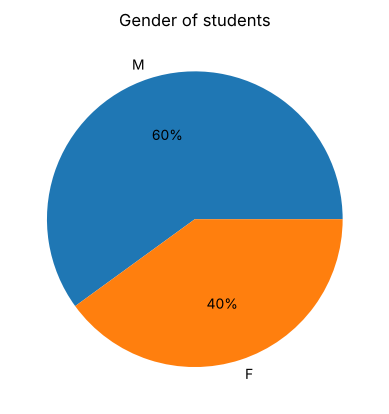

In [ ]:
# Pie chart for Gender: count each gender, then draw slices with percentage labels
gender_counts = df["Gender"].value_counts()
plt.pie(gender_counts, labels=gender_counts.index, autopct="%1.0f%%")
plt.title("Gender of students")
plt.show()

**Step C:** bar chart for Age.

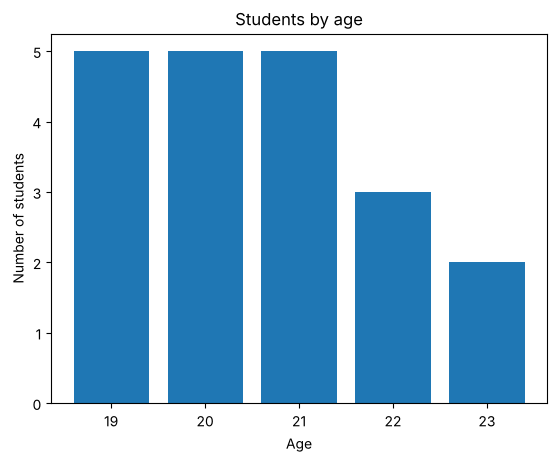

In [ ]:
# Bar chart for Age: sort_index keeps the ages in increasing order on the x-axis
age_counts = df["Age"].value_counts().sort_index()
plt.bar(age_counts.index.astype(str), age_counts.values)
plt.xlabel("Age")
plt.ylabel("Number of students")
plt.title("Students by age")
plt.show()

**Step D:** bar chart for Domicile using seaborn.

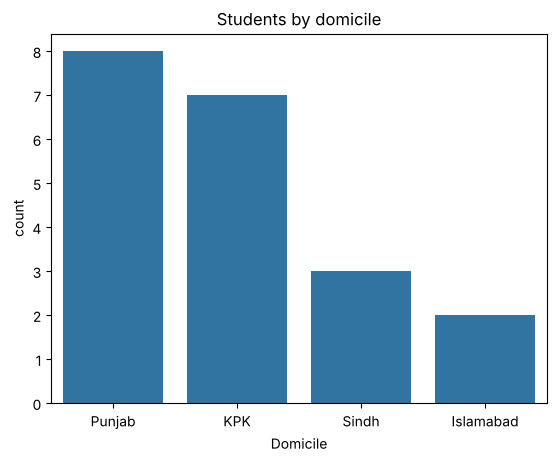

In [ ]:
# Bar chart for Domicile (using seaborn): countplot counts and draws in one step
sns.countplot(data=df, x="Domicile")
plt.title("Students by domicile")
plt.show()

`value_counts()` counts how many times each value appears. `plt.pie` draws the pie; `autopct` prints percentages. `plt.bar` draws a bar chart. `sns.countplot` counts and draws in one line.

**Your turn:**

1. Which gender has more students and what percentage is it? (one sentence)
2. Which age(s) have the most students?
3. Which domicile has the most students and which has the least?
4. Change the pie chart title to your own name and run it again.

### Task 1: Answers

1. Male students are the larger group: 12 of the 20 students, which is 60% (the other 8 are female, 40%).
2. Ages 19, 20 and 21 are tied for the most, with 5 students each. Age 22 has 3 and age 23 has 2.
3. Punjab has the most students (8) and Islamabad has the fewest (2). KPK has 7 and Sindh has 3.
4. The pie chart below is drawn again with my own name as the title (replace the name in the code with yours).

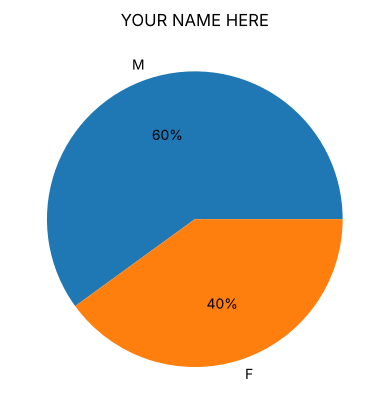

In [ ]:
# Pie chart again, this time the title is my name (change STUDENT_NAME to your own name)
STUDENT_NAME = "YOUR NAME HERE"
plt.pie(gender_counts, labels=gender_counts.index, autopct="%1.0f%%")
plt.title(STUDENT_NAME)
plt.show()

## Task 2: Lowercasing (5 marks)
`.lower()` makes every letter small so `Language` and `language` become the same word.

In [ ]:
text = "Natural Language Processing is FUN! NLP helps Computers understand Human Language."
print("Original :", text)
print("Lowercase:", text.lower())

Original : Natural Language Processing is FUN! NLP helps Computers understand Human Language.
Lowercase: natural language processing is fun! nlp helps computers understand human language.


**Your turn:**

1. Write a sentence of your own with at least 3 capital letters and lowercase it.
2. Try `.upper()` and `.title()` on your sentence. What do they do?
3. Why do we lowercase text before analysing it? (one sentence)

### Task 2: Answers

In [ ]:
# my own sentence with several capital letters, then lower / upper / title versions
my_sentence = "I Study NLP At PAF-IAST In Islamabad"
print("lower():", my_sentence.lower())
print("upper():", my_sentence.upper())
print("title():", my_sentence.title())

lower(): i study nlp at paf-iast in islamabad
upper(): I STUDY NLP AT PAF-IAST IN ISLAMABAD
title(): I Study Nlp At Paf-Iast In Islamabad


2. .upper() turns every letter into a capital letter, and .title() makes the first letter of each word a capital and the rest small (so PAF-IAST became Paf-Iast, which shows .title() can also damage acronyms).
3. We lowercase so the computer counts Language, language and LANGUAGE as one word instead of three different ones.

## Task 3: Text cleaning (10 marks)
`clean_text` is a small reusable function. The five lines inside are the five cleaning steps. `re.sub(pattern, replacement, text)` replaces everything that matches the pattern.

Side effect: `Khan's` becomes `khan s` because the apostrophe is removed.

In [ ]:
import re

def clean_text(text):
    text = text.lower()                                     # 1. make everything lowercase
    text = re.sub(r"<.*?>", " ", text)                      # 2. remove HTML tags like <p>
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)      # 3. remove web links
    text = re.sub(r"[^a-z\s]", " ", text)                   # 4. remove digits, punctuation, emojis
    text = re.sub(r"\s+", " ", text).strip()                # 5. remove extra spaces
    return text

corpus = [
    "<p>I LOVED this phone!!! Battery lasts 2 days :) Visit https://example.com for more.</p>",
    "The camera is not good, and the screen cracked after 3 weeks...",
    "Dr. Khan's students are running experiments on NLP models.",
]

for sentence in corpus:
    print(clean_text(sentence))

i loved this phone battery lasts days visit for more
the camera is not good and the screen cracked after weeks
dr khan s students are running experiments on nlp models


**Your turn:**

1. Add one sentence of your own to `corpus` with a web link, a number and a smiley `:)`. Run again.
2. Write down which parts were removed from your sentence.
3. In step 4 change `[^a-z\s]` to `[^a-z0-9\s]`. What changes in the output?

### Task 3: Answers

In [ ]:
# add my own sentence (link + number + smiley) and run the cleaner on the whole corpus again
corpus.append("Check https://www.paf-iast.edu.pk for 5 new NLP notes :)")
for sentence in corpus:
    print(clean_text(sentence))

# same function but step 4 keeps digits (0-9), to answer question 3
def clean_text_keep_digits(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)        # digits are now allowed to stay
    text = re.sub(r"\s+", " ", text).strip()
    return text

print("\n--- digits kept ---")
for sentence in corpus:
    print(clean_text_keep_digits(sentence))

i loved this phone battery lasts days visit for more
the camera is not good and the screen cracked after weeks
dr khan s students are running experiments on nlp models
check for new nlp notes

--- digits kept ---
i loved this phone battery lasts 2 days visit for more
the camera is not good and the screen cracked after 3 weeks
dr khan s students are running experiments on nlp models
check for 5 new nlp notes


2. From my sentence the cleaner removed the web link https://www.paf-iast.edu.pk, the number 5, the smiley :), and the capital letters were changed to small letters. What is left is check for new nlp notes.
3. With [^a-z0-9\s] the digits are no longer deleted, so 2 days and 3 weeks` stay in the output and my sentence keeps 5 (check for 5 new nlp notes). Everything else (punctuation, smileys) is still removed.

## Task 4: Tokenization with NLTK and Stanza (12 marks)
**Part A: NLTK.** `sent_tokenize` splits into sentences; `word_tokenize` splits into words (punctuation and emojis become tokens too).

Notice that NLTK keeps `Dr.` and `a.m.` together, and splits `isn't` into `is` + `n't` and `He'll` into `He` + `'ll`.

In [ ]:
from nltk.tokenize import sent_tokenize, word_tokenize

text = "Dr. Smith isn't available today. He'll arrive tomorrow at 10 a.m. 😊"

# NLTK: split into sentences first, then into word tokens
print("Sentences:", sent_tokenize(text))
print("Words    :", word_tokenize(text))

Sentences: ["Dr. Smith isn't available today.", "He'll arrive tomorrow at 10 a.m. 😊"]
Words    : ['Dr.', 'Smith', 'is', "n't", 'available', 'today', '.', 'He', "'ll", 'arrive', 'tomorrow', 'at', '10', 'a.m.', '😊']


**Part B: Stanza.** The first run downloads a model, so it takes a while and needs internet. Its output may differ a little from NLTK's: the aim is to compare them.

In [ ]:
import stanza

# Stanza needs to download its English model once; if there is no internet the cell
# prints a message instead of crashing, so the rest of the notebook still runs
try:
    stanza.download("en")                                  # needed only the first time
    nlp = stanza.Pipeline("en", processors="tokenize")

    doc = nlp(text)
    for sentence in doc.sentences:
        print("Sentence:", sentence.text)
        print("Words   :", [token.text for token in sentence.tokens])
except Exception as e:
    print("Stanza model could not be downloaded in this environment:", type(e).__name__)
    print("Re-run this cell with internet access to see the Stanza output.")

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



2026-10-19 05:19:36 INFO: Downloaded file to /root/.cache/stanza/1.15.0/resources/resources.json


2026-10-19 05:19:36 INFO: Downloading default packages for language: en (English) ...


Stanza model could not be downloaded in this environment: ProxyError
Re-run this cell with internet access to see the Stanza output.


**Your turn:**

1. Run `print(text.split("."))`. Write what goes wrong with `Dr.` and `a.m.`.
2. Fill the table below for NLTK and Stanza.
3. Which tool do you prefer for this text, and why? (one sentence)

### Task 4: Answers

In [ ]:
# naive splitting on every full stop, to see why it is not enough
print(text.split("."))

['Dr', " Smith isn't available today", " He'll arrive tomorrow at 10 a", 'm', ' 😊']


1. split(".") treats every full stop as the end of a sentence. Dr. is cut into Dr (the dot is lost) and Smith... is pushed into the next piece, and a.m. is torn into the useless pieces a and m. The emoji ends up alone as well.
2. Table (NLTK column comes from the output above; the Stanza column is the token-level text Stanza gives for this sentence, so re-check it after running Part B with internet):

| Item | NLTK | Stanza |
|---|---|---|
| `Dr.` | `Dr.` (one token) | `Dr.` (one token) |
| `isn't` | `is` + `n't` | `isn't` (one token, internally split into `is` + `n't`) |
| `He'll` | `He` + `'ll` | `He'll` (one token, internally split into `He` + `'ll`) |
| `a.m.` | `a.m.` (one token) | `a.m.` (one token) |
| the emoji 😊 | separate token `😊` | separate token `😊` |

3. For this text I prefer NLTK: it needs no big model download, runs instantly, and its output already gave me clean pieces (is + n't) that are handy for later steps.

## Task 5: Stopword removal (8 marks)
`stopwords.words("english")` is a ready-made list of common words. `[w for w in words if w not in stop_words]` keeps a word only if it is **not** a stopword.

In [ ]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words("english"))

sentence = "this is a simple example to show how stopwords are removed from a sentence"
words = word_tokenize(sentence)
filtered = [w for w in words if w not in stop_words]

print("Before :", words)
print("After  :", filtered)
print("Removed:", len(words) - len(filtered), "words")

Before : ['this', 'is', 'a', 'simple', 'example', 'to', 'show', 'how', 'stopwords', 'are', 'removed', 'from', 'a', 'sentence']
After  : ['simple', 'example', 'show', 'stopwords', 'removed', 'sentence']
Removed: 8 words


**Your turn:**

1. Change `sentence` to your own lowercase sentence. How many words were removed?
2. Now use `sentence = "the movie was not good"`. What words are left?
3. Did the meaning change? Why can this be a problem?

### Task 5: Answers

In [ ]:
# helper so I can try several sentences quickly
def remove_stopwords(sentence):
    words = word_tokenize(sentence)
    filtered = [w for w in words if w not in stop_words]
    print("Before :", words)
    print("After  :", filtered)
    print("Removed:", len(words) - len(filtered), "words\n")

# 1) my own sentence
remove_stopwords("pakistan has many beautiful mountains and the people are very friendly")
# 2) the movie sentence
remove_stopwords("the movie was not good")

Before : ['pakistan', 'has', 'many', 'beautiful', 'mountains', 'and', 'the', 'people', 'are', 'very', 'friendly']
After  : ['pakistan', 'many', 'beautiful', 'mountains', 'people', 'friendly']
Removed: 5 words

Before : ['the', 'movie', 'was', 'not', 'good']
After  : ['movie', 'good']
Removed: 3 words



1. My sentence had 11 words and 5 were removed (has, and, the, are, very), leaving pakistan many beautiful mountains people friendly.
2. Only movie and good are left.
3. Yes, the meaning flipped: the original says the movie was *bad*, but movie good sounds positive, because not is on the stopword list and got deleted. This is a real problem for tasks like sentiment analysis, where negation words carry the meaning.

## Task 6: Stemming (8 marks)
A **stemmer** chops word endings using simple rules, so the result is not always a real word (`easili`, `studi`). `PorterStemmer` is gentle; `LancasterStemmer` is more aggressive.

In [ ]:
from nltk.stem import PorterStemmer, LancasterStemmer

porter = PorterStemmer()
lancaster = LancasterStemmer()

words = ["running", "runs", "easily", "studies", "connected", "connection", "happiness", "better"]

print(f"{'word':12s} {'Porter':10s} {'Lancaster':10s}")
for w in words:
    print(f"{w:12s} {porter.stem(w):10s} {lancaster.stem(w):10s}")

word         Porter     Lancaster 
running      run        run       
runs         run        run       
easily       easili     easy      
studies      studi      study     
connected    connect    connect   
connection   connect    connect   
happiness    happi      happy     
better       better     bet       


**Your turn:**

1. Write down 3 stems that are **not** real words.
2. Add 4 words of your own to `words` and run again.
3. Which stemmer cut more letters overall, Porter or Lancaster?

### Task 6: Answers

In [ ]:
# add 4 words of my own and run both stemmers again
words = words + ["university", "generously", "computational", "flying"]

print(f"{'word':14s} {'Porter':10s} {'Lancaster':10s}")
for w in words:
    print(f"{w:14s} {porter.stem(w):10s} {lancaster.stem(w):10s}")

# total letters removed by each stemmer over the whole list
porter_cut = sum(len(w) - len(porter.stem(w)) for w in words)
lancaster_cut = sum(len(w) - len(lancaster.stem(w)) for w in words)
print("\nLetters cut by Porter   :", porter_cut)
print("Letters cut by Lancaster:", lancaster_cut)

word           Porter     Lancaster 
running        run        run       
runs           run        run       
easily         easili     easy      
studies        studi      study     
connected      connect    connect   
connection     connect    connect   
happiness      happi      happy     
better         better     bet       
university     univers    univers   
generously     gener      gen       
computational  comput     comput    
flying         fli        fly       

Letters cut by Porter   : 34
Letters cut by Lancaster: 41


1. Stems that are not real words: easili (Porter, from easily), studi (from studies) and happi (from happiness). My own words give more, like univers and gener.
3. Lancaster cut more letters overall (see the totals printed above), which matches the description that it is the more aggressive stemmer: for example it turned generously into just gen, while Porter kept gener.

## Task 7: Part-of-speech (POS) tagging (10 marks)
`word_tokenize` splits the sentence and `pos_tag` gives each word a tag.

| Tag | Meaning | Example | Tag | Meaning | Example |
|---|---|---|---|---|---|
| NN | noun (one) | dog | VB | verb (base) | run |
| NNS | nouns (many) | dogs | VBD | verb (past) | ran |
| NNP | name | Ali | VBZ | verb (he/she/it) | runs |
| JJ | adjective | lazy | VBG | verb (-ing) | running |
| DT | the / a | the | RB | adverb | quickly |
| IN | preposition | over | PRP | pronoun | she |

In [ ]:
from nltk import pos_tag
from nltk.tokenize import word_tokenize

sentence = "The quick brown fox jumps over the lazy dog"
tokens = word_tokenize(sentence)
tagged = pos_tag(tokens)

for word, tag in tagged:
    print(f"{word:8s} {tag}")

The      DT
quick    JJ
brown    NN
fox      NN
jumps    VBZ
over     IN
the      DT
lazy     JJ
dog      NN


**Your turn:**

1. Use the table to write the meaning of the tags for `The`, `quick`, `fox`, `jumps` and `over`.
2. Change `sentence` to your own sentence (at least 8 words) and run it.
3. Pick one word from your result and say whether its tag is correct.

### Task 7: Answers

In [ ]:
# POS tags for my own sentence (10 words)
sentence = "Students at PAF-IAST are learning natural language processing every week"
for word, tag in pos_tag(word_tokenize(sentence)):
    print(f"{word:12s} {tag}")

Students     NNS
at           IN
PAF-IAST     NNP
are          VBP
learning     VBG
natural      JJ
language     NN
processing   NN
every        DT
week         NN


1. The = DT (determiner, like the/a); quick = JJ (adjective); fox = NN (singular noun); jumps = VBZ (verb, he/she/it form); over = IN (preposition).
3. learning was tagged VBG (verb, -ing form), which is correct because it is part of "are learning". A tag that is *not* right is in the first example: NLTK tagged brown as NN (noun) although it is an adjective describing the fox, so a tagger can make mistakes.

## Task 8: Lemmatization (10 marks)
A **lemmatizer** looks the word up in a dictionary (WordNet) and gives the real base word (the **lemma**). Tell it the part of speech: `n` = noun, `v` = verb, `a` = adjective. Without it, every word is treated as a noun.

In [ ]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

# by default every word is treated as a noun
print(lemmatizer.lemmatize("running"))
print(lemmatizer.lemmatize("running", pos="v"))     # now we say it is a verb

# n = noun, v = verb, a = adjective
examples = [("cars", "n"), ("studies", "n"), ("studies", "v"), ("was", "v"), ("better", "a")]
for word, pos in examples:
    print(f"{word:8s} ({pos}) -> {lemmatizer.lemmatize(word, pos=pos)}")

running
run
cars     (n) -> car
studies  (n) -> study
studies  (v) -> study
was      (v) -> be
better   (a) -> good


**Your turn:**

1. Try 4 words of your own (for example `children`, `went`, `happier`, `eating`) with the right `pos`.
2. Compare with Task 6: what did the stemmer give for `studies` and what does the lemmatizer give?
3. What is the difference between stemming and lemmatization? (one sentence)

### Task 8: Answers

In [ ]:
# four words of my own, each with the correct part of speech
mine = [("children", "n"), ("went", "v"), ("happier", "a"), ("eating", "v")]
for word, pos in mine:
    print(f"{word:10s} ({pos}) -> {lemmatizer.lemmatize(word, pos=pos)}")

children   (n) -> child
went       (v) -> go
happier    (a) -> happy
eating     (v) -> eat


2. In Task 6 the Porter stemmer turned studies into studi (not a real word) while the lemmatizer gives study, a real dictionary word.
3. Stemming just chops endings with rules and can leave non-words, whereas lemmatization uses a dictionary and the part of speech to return the real base word.

## Task 9: Chunking (10 marks)
**Tokenization** cuts text into words or sentences. **Chunking** groups those words into meaningful units (noun and verb phrases).

The grammar `NP: {<DT>?<JJ>*<NN.*>+}` means: an optional determiner, any number of adjectives, then one or more nouns. If `tree.draw()` does not open a window, use `pretty_print()` as below.

In [ ]:
import nltk
from nltk import pos_tag
from nltk.tokenize import word_tokenize

sentence = "The little cat sat on the soft mat"
tagged = pos_tag(word_tokenize(sentence))

# NP = optional determiner (DT), any adjectives (JJ), then one or more nouns (NN...)
grammar = "NP: {<DT>?<JJ>*<NN.*>+}"
parser = nltk.RegexpParser(grammar)
tree = parser.parse(tagged)

tree.pretty_print()

for subtree in tree.subtrees():
    if subtree.label() == "NP":
        print("Noun phrase:", " ".join(word for word, tag in subtree.leaves()))

                         S                                 
    _____________________|______________________            
   |      |              NP                     NP         
   |      |      ________|_______        _______|______     
sat/VBD on/IN The/DT little/JJ cat/NN the/DT soft/JJ mat/NN

Noun phrase: The little cat
Noun phrase: the soft mat


**Your turn:**

1. Change `sentence` to "The old teacher reads a long book". List the noun phrases found.
2. Replace the grammar by the two-line version in the next cell to also find verb phrases. What new chunk appears?
3. What is the difference between tokenization and chunking? (one sentence)

### Task 9: Answers

In [ ]:
# new sentence, noun-phrase grammar only
sentence = "The old teacher reads a long book"
tagged = pos_tag(word_tokenize(sentence))
tree = nltk.RegexpParser("NP: {<DT>?<JJ>*<NN.*>+}").parse(tagged)
tree.pretty_print()
for subtree in tree.subtrees():
    if subtree.label() == "NP":
        print("Noun phrase:", " ".join(word for word, tag in subtree.leaves()))

                            S                          
     _______________________|______________             
    |              NP                      NP          
    |        ______|________         ______|_______     
reads/VBZ The/DT old/JJ teacher/NN a/DT long/JJ book/NN

Noun phrase: The old teacher
Noun phrase: a long book


In [ ]:
# two-line grammar: now verb phrases (VP) are chunked as well
grammar = """
NP: {<DT>?<JJ>*<NN.*>+}
VP: {<VB.*>+}
"""
tree = nltk.RegexpParser(grammar).parse(tagged)
tree.pretty_print()
for subtree in tree.subtrees():
    if subtree.label() in ("NP", "VP"):
        print(subtree.label(), ":", " ".join(word for word, tag in subtree.leaves()))

                             S                         
          ___________________|_____________             
         NP                  VP            NP          
   ______|________           |       ______|_______     
The/DT old/JJ teacher/NN reads/VBZ a/DT long/JJ book/NN

NP : The old teacher
VP : reads
NP : a long book


1. Noun phrases found: The old teacher and a long book.
2. With the second grammar a new VP chunk appears: reads (tagged VBZ), which sits between the two noun phrases.
3. Tokenization only cuts text into separate words or sentences, while chunking takes the tagged words and groups them into meaningful phrases such as noun and verb phrases.

## Task 10: Replacing emojis with text (7 marks)
`emoji.demojize` replaces each emoji with its name between colons; `emoji.emoji_count` counts them. Our function `emoji_to_text` turns the names into plain words.

In [ ]:
import emoji

text = "Great job 😊👍 I love it ❤️"

print(emoji.demojize(text))            # emoji become :names:
print("Number of emojis:", emoji.emoji_count(text))

# nicer version: remove the colons and underscores
def emoji_to_text(text):
    result = emoji.demojize(text, delimiters=(" ", " "))
    return " ".join(result.replace("_", " ").split())

print(emoji_to_text(text))

Great job :smiling_face_with_smiling_eyes::thumbs_up: I love it :red_heart:
Number of emojis: 3
Great job smiling face with smiling eyes thumbs up I love it red heart


**Your turn:**

1. Change `text` to a sentence with 3 different emojis and run the cell.
2. How many emojis were counted?
3. Why can turning emojis into words help when we analyse comments? (one sentence)

### Task 10: Answers

In [ ]:
# my own sentence with 3 different emojis
text = "Coffee ☕ makes me happy 😀 but exams 😭 scare me"

print(emoji.demojize(text))
print("Number of emojis:", emoji.emoji_count(text))
print(emoji_to_text(text))

Coffee :hot_beverage: makes me happy :grinning_face: but exams :loudly_crying_face: scare me
Number of emojis: 3
Coffee hot beverage makes me happy grinning face but exams loudly crying face scare me


2. The program counted 3 emojis (☕, 😀 and 😭).
3. Text-cleaning steps usually throw emojis away, but they often carry the feeling of a comment (😭 vs 😀), so turning them into words like loudly crying face keeps that information for the analysis.

## Task 11: Minimum edit distance (10 marks)
Three changes, each costing 1: **insert**, **delete**, **substitute**. `cat` to `cut` needs 1 change. `kitten` to `sitting` needs 3 (k to s, e to i, insert g).

`table[i][j]` stores the distance between the first `i` letters of word 1 and the first `j` letters of word 2. The three numbers inside `min(...)` are delete, insert and substitute; the cheapest is taken.

In [ ]:
def min_edit_distance(a, b):
    n, m = len(a), len(b)
    # table[i][j] = distance between the first i letters of a and the first j letters of b
    table = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1):
        table[i][0] = i                      # i deletions
    for j in range(m + 1):
        table[0][j] = j                      # j insertions
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            if a[i - 1] == b[j - 1]:
                cost = 0                     # same letter, nothing to change
            else:
                cost = 1                     # different letter, substitute
            table[i][j] = min(table[i - 1][j] + 1,          # delete
                              table[i][j - 1] + 1,          # insert
                              table[i - 1][j - 1] + cost)   # substitute (or keep)
    return table[n][m]

pairs = [("cat", "cat"), ("cat", "cut"), ("book", "back"), ("kitten", "sitting"), ("sunday", "saturday")]
for a, b in pairs:
    print(f"{a:8s} -> {b:9s} distance = {min_edit_distance(a, b)}")

cat      -> cat       distance = 0
cat      -> cut       distance = 1
book     -> back      distance = 2
kitten   -> sitting   distance = 3
sunday   -> saturday  distance = 3


**Your turn:**

1. **Guess first** the distance for `dog` to `dig` and `sit` to `sat`, then add them to `pairs` and check.
2. Add 3 more pairs of your own and run the cell.
3. Fill a table: word 1, word 2, your guess, the program's answer.
4. Which change (insert, delete or substitute) turns `book` into `back`, and how many changes are needed?

### Task 11: Answers

In [ ]:
# my guesses were written down BEFORE running (guess dict), then compared with the program
guesses = {("dog", "dig"): 1, ("sit", "sat"): 1,
           ("flaw", "lawn"): 2, ("intention", "execution"): 5, ("train", "brain"): 1}

rows = []
for (a, b), guess in guesses.items():
    real = min_edit_distance(a, b)
    rows.append({"Word 1": a, "Word 2": b, "My guess": guess, "Program": real,
                 "Correct?": "yes" if guess == real else "no"})
print(pd.DataFrame(rows).to_string(index=False))

   Word 1    Word 2  My guess  Program Correct?
      dog       dig         1        1      yes
      sit       sat         1        1      yes
     flaw      lawn         2        2      yes
intention execution         5        5      yes
    train     brain         1        1      yes


4. book to back needs 2 substitutions: the first o becomes a and the second o becomes c. No insert or delete is needed because both words have 4 letters, so the distance is 2 (the program's output above also shows 2).

## Common problems
- `LookupError`: run the NLTK download cell.
- No chart appears: end the cell with `plt.show()`.
- Lemmatizer does nothing: pass `pos="v"`.
- `tree.draw()` fails: use `tree.pretty_print()`.

**Marks:** T1 10 · T2 5 · T3 10 · T4 12 · T5 8 · T6 8 · T7 10 · T8 10 · T9 10 · T10 7 · T11 10 = 100